# Drawing: A New Way To Search

We teach models to recognise hand-drawn QuickDraw doodles (28×28 pixels, 50 classes), reproducing the report's
models and adding XGBoost, so that a quick sketch could be used as a search query.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
# Works whether Jupyter starts in the project root or demonstration/.
ROOT = str(next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src" / "data.py").is_file()))
os.chdir(os.path.join(ROOT, "demonstration"))
sys.path[:0] = [ROOT, os.path.join(ROOT, "src")]
sys.dont_write_bytecode = True                    # leave src/ untouched (no __pycache__ files)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from IPython.display import display

import data
from train_cnn import build

print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
RESULTS = os.path.join(ROOT, "results")  # only read
rng = np.random.default_rng(0)           # change the seed to see other drawings

GPU available: False


## The data: 50 classes, 2,000 test drawings each

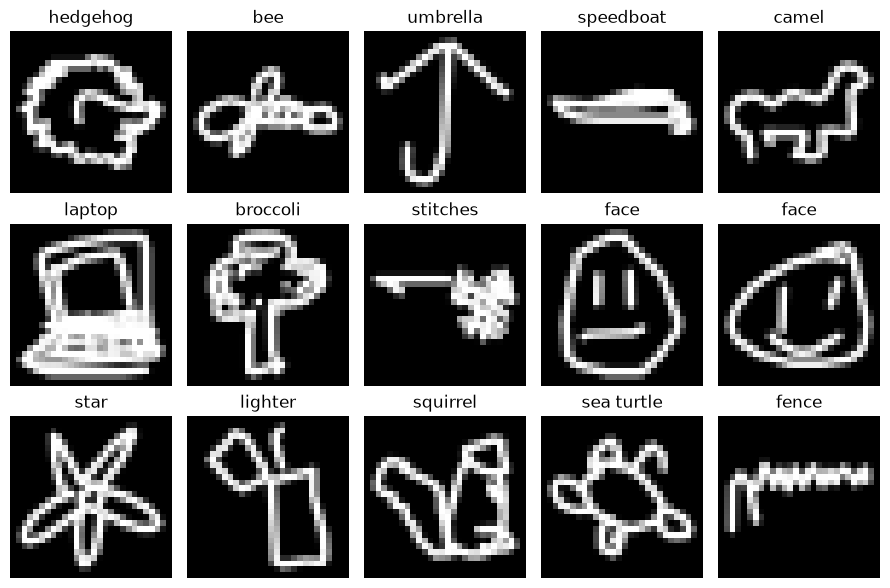

In [2]:
d = np.load(data._path(50))
X_TEST, Y_TEST = d["X_test"], d["y_test"]  # 100,000 drawings, white ink on black, values 0-255
NAMES = [str(n) for n in d["class_names"]]

fig, axs = plt.subplots(3, 5, figsize=(9, 6))
for ax, i in zip(axs.flat, rng.choice(len(X_TEST), 15, replace=False)):
    ax.imshow(X_TEST[i].reshape(28, 28), cmap="gray")
    ax.set_title(NAMES[Y_TEST[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Live: logistic regression on 3 classes

The same setting as `src/train_lr.py`: raw pixels, L-BFGS, 100 iterations.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

xtr, ytr, xdv, ydv, _, _, names3 = data.load(3, "raw")
clf = LogisticRegression(solver="lbfgs", max_iter=100, random_state=0)
t = time.time()
with warnings.catch_warnings(record=True) as training_warnings:
    warnings.simplefilter("always", ConvergenceWarning)  # stops at 100 iterations before converging, as in the reference
    clf.fit(xtr, ytr)
print(f"classes: {', '.join(names3)}")
print(f"validation accuracy: {100 * clf.score(xdv, ydv):.1f}%   training time: {time.time() - t:.1f} s")
for warning in training_warnings:
    if issubclass(warning.category, ConvergenceWarning):
        print("The reference stops logistic regression at 100 iterations; it may not fully converge. This is expected for this reproduction.")
    else:
        warnings.warn(str(warning.message), warning.category)


classes: eraser, belt, banana
validation accuracy: 79.3%   training time: 0.9 s
The reference stops logistic regression at 100 iterations; it may not fully converge. This is expected for this reproduction.


## Training evidence (from `results/`, no retraining)

Left: the CNN V2 training curve on 50 classes. Right: the XGBoost learning curve on 50 classes, which levels off
long before training stops. The table lists every run behind our results.

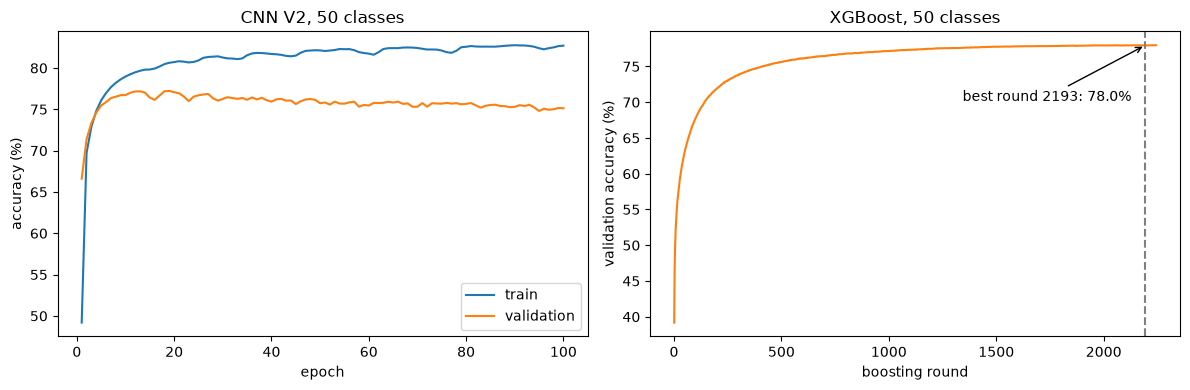

In [4]:
h = pd.read_csv(os.path.join(RESULTS, "figures", "CNN_V2_50_raw_s7", "history.csv"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(h.epoch, 100 * h.accuracy, label="train")
a1.plot(h.epoch, 100 * h.val_accuracy, label="validation")
a1.set(title="CNN V2, 50 classes", xlabel="epoch", ylabel="accuracy (%)")
a1.legend()

ext = os.path.join(RESULTS, "xgb_extended")  # first run, then its continuation until early stopping
curves = [os.path.join(ext, "phase8_50_curve.csv"), os.path.join(ext, "runs", "A1", "curve.csv")]
if all(map(os.path.exists, curves)):
    c = pd.concat([pd.read_csv(p) for p in curves]).drop_duplicates("round").reset_index(drop=True)
    b = c.loc[c.dev_mlogloss.idxmin()]
    a2.plot(c["round"], 100 * c.dev_acc, color="C1")
    a2.axvline(b["round"], ls="--", color="gray")
    a2.annotate(f"best round {b['round']:.0f}: {100 * b.dev_acc:.1f}%", (b["round"], 100 * b.dev_acc),
                xytext=(-10, -40), textcoords="offset points", ha="right", arrowprops={"arrowstyle": "->"})
    a2.set(title="XGBoost, 50 classes", xlabel="boosting round", ylabel="validation accuracy (%)")
else:
    a2.axis("off")
    a2.text(0.5, 0.5, "XGBoost curve files are not in results/ on this machine", ha="center")
plt.tight_layout()
plt.show()

In [5]:
runs = pd.read_csv(os.path.join(RESULTS, "all_results.csv"))
p = runs.params.map(json.loads)
# compute time: the whole search for XGBoost, run time plus the one-off feature extraction for transfer learning
search = p.map(lambda q: q.get("search_time_s", np.nan)).astype(float)
compute = search.fillna(runs.total_time_s + p.map(lambda q: q.get("extract_time_s", 0)))
table = pd.DataFrame({"Run": runs.run_id, "Hardware": runs.hardware, "Training time (s)": runs.fit_time_s,
                      "Compute time (s)": compute}).round(1)
pd.set_option("display.max_rows", 100)
display(table)
print(f"Total compute time: {compute.sum() / 3600:.1f} h over {len(runs)} runs")

,Run,Hardware,Training time (s),Compute time (s)
0,LR_logreg_3_raw_s0,CPU,19.9,20.3
1,LR_logreg_10_raw_s0,CPU,20.0,20.5
2,LR_logreg_50_raw_s0,CPU,86.0,87.0
3,SVM_poly_3_scaled_s0,CPU,37.7,41.2
4,CNN_V1_3_raw_s7,GPU,39.4,40.7
5,SVM_linear_3_scaled_s0,CPU,38.0,43.1
6,SVM_rbf_3_scaled_s0,CPU,41.4,45.0
7,SVM_sigmoid_3_scaled_s0,CPU,43.4,47.8
8,CNN_V2_3_raw_s7,GPU,37.7,38.9
9,CNN_V1_3_binarized_s7,GPU,43.7,45.1


Total compute time: 22.1 h over 46 runs


## The trained CNN V1 (50 classes) on test drawings

Green titles are correct predictions, red ones are mistakes. The input is the raw 0–255 image, exactly as in training.

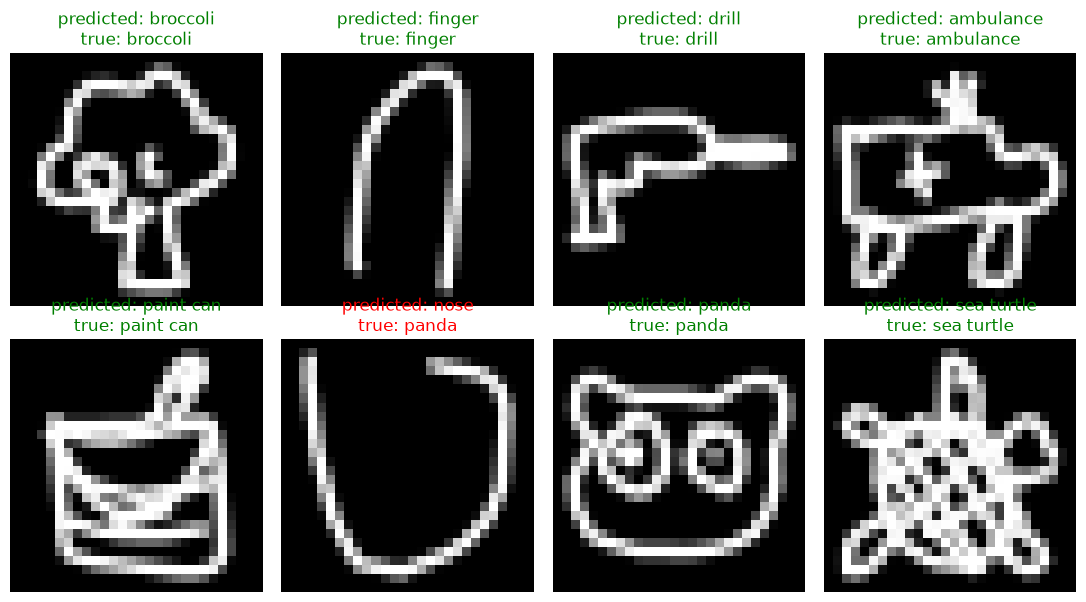

CNN V1 test accuracy on all 100,000 test drawings: 81.1%


In [6]:
cnn = build("V1", 50)
cnn.load_weights("models/cnn_v1_50_raw.weights.h5")
probs = cnn.predict(X_TEST.reshape(-1, 28, 28, 1).astype(np.float32), batch_size=500, verbose=0)
pred = probs.argmax(1)

fig, axs = plt.subplots(2, 4, figsize=(11, 6))
for ax, i in zip(axs.flat, rng.choice(len(X_TEST), 8, replace=False)):
    ax.imshow(X_TEST[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"predicted: {NAMES[pred[i]]}\ntrue: {NAMES[Y_TEST[i]]}",
                 color="green" if pred[i] == Y_TEST[i] else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"CNN V1 test accuracy on all {len(Y_TEST):,} test drawings: {100 * np.mean(pred == Y_TEST):.1f}%")

## Try your own drawing

Draw **one object** from the 50 classes below with **thick, simple strokes**, dark on a light background (or light
on dark), in any paint program or on paper with a photo, and save it as PNG or JPG in `my_drawings/`. Fill most of
the canvas, avoid shading and text. Two examples are included: `star.png` and `umbrella.jpg`.

**The 50 classes:** aircraft carrier, ambulance, banana, beard, bee, belt, broccoli, camel, castle, chair, drill, eraser, face, fence, finger, floor lamp, grapes, hammer, harp, hat, hedgehog, hockey stick, kangaroo, laptop, leaf, lighter, lobster, nose, paint can, panda, peas, pond, rain, screwdriver, sea turtle, shark, skull, snake, snowflake, speedboat, spreadsheet, squirrel, star, stitches, sweater, teddy-bear, The Mona Lisa, trumpet, umbrella, wristwatch

The drawing is converted the way QuickDraw stores its drawings: grayscale, inverted to white ink on black if the
background is light, cropped to the drawing, padded to a square with a margin and shrunk to 28×28, with values 0–255.

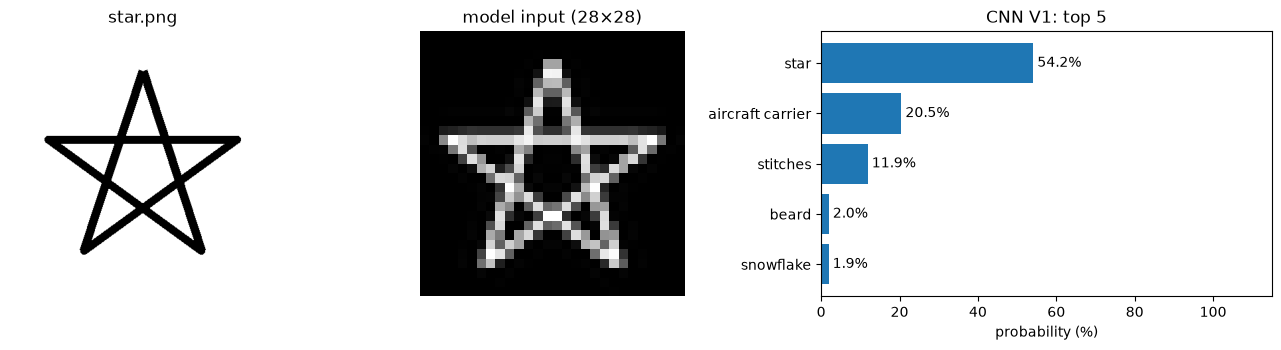

In [7]:
def to_quickdraw(path):
    """Any PNG/JPG -> 28x28 float32 image like the training data (white ink on black, 0-255)."""
    g = np.asarray(Image.open(path).convert("L"), dtype=np.float32)
    if g.mean() > 127:  # light background: invert
        g = 255 - g
    ys, xs = np.nonzero(g > 0.2 * g.max())
    if len(ys) == 0:
        raise ValueError(f"no drawing found in {path}")
    g = g[ys.min():ys.max() + 1, xs.min():xs.max() + 1]  # crop to the drawing
    side = int(max(g.shape) * 1.2)                     # square with a 10% margin on each side
    sq = np.zeros((side, side), np.float32)
    top, left = (side - g.shape[0]) // 2, (side - g.shape[1]) // 2
    sq[top:top + g.shape[0], left:left + g.shape[1]] = g
    small = np.asarray(Image.fromarray(sq.astype(np.uint8)).resize((28, 28), Image.LANCZOS), np.float32)
    return small * 255 / max(small.max(), 1)  # strokes fade when shrunk: stretch back to the full 0-255 range


def top5_bars(ax, p, title):
    best = p.argsort()[::-1][:5][::-1]
    ax.barh([NAMES[i] for i in best], 100 * p[best], color="C0")
    for y, i in enumerate(best):
        ax.text(100 * p[i] + 1, y, f"{100 * p[i]:.1f}%", va="center")
    ax.set(xlim=(0, 115), xlabel="probability (%)", title=title)


def predict_my_drawing(path):
    img = to_quickdraw(path)
    p = cnn.predict(img.reshape(1, 28, 28, 1), verbose=0)[0]
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.6]})
    a.imshow(Image.open(path))
    a.set_title(os.path.basename(path))
    b.imshow(img, cmap="gray", vmin=0, vmax=255)
    b.set_title("model input (28×28)")
    for ax in (a, b):
        ax.axis("off")
    top5_bars(c, p, "CNN V1: top 5")
    plt.tight_layout()
    plt.show()
    return img, p


MY_DRAWING = "my_drawings/star.png"  # put your own file in my_drawings/ and change this
img, p_cnn = predict_my_drawing(MY_DRAWING)

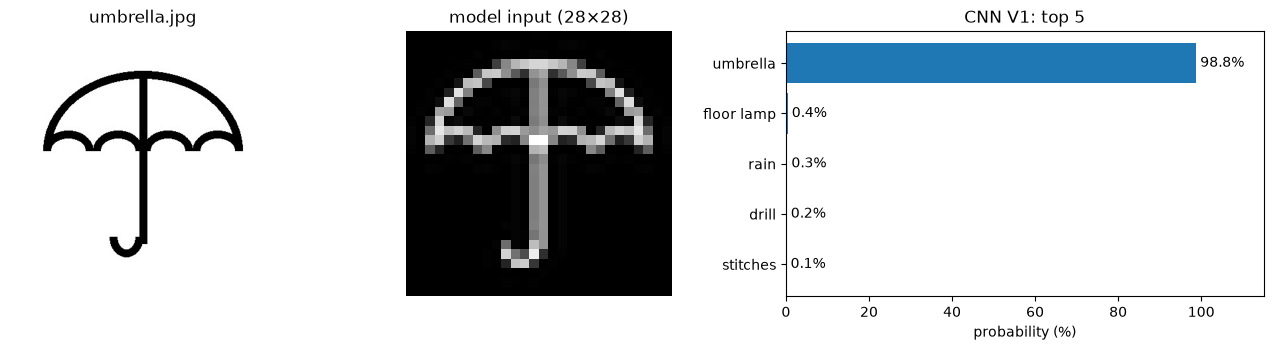

In [18]:
predict_my_drawing("my_drawings/umbrella.jpg");

## The same drawing through the final XGBoost model

The final 50-class XGBoost model (2,193 boosting rounds) is included in this project and runs locally on the Mac CPU.

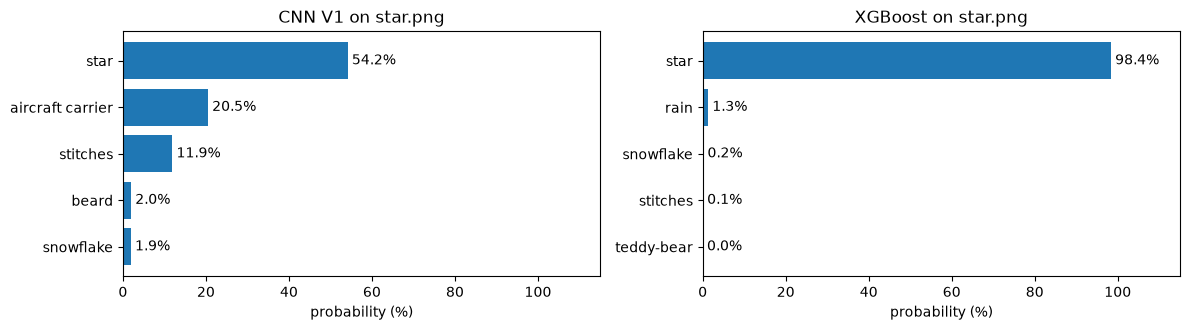

In [8]:
XGB_MODEL = os.path.join(RESULTS, "xgb_extended", "runs", "A1", "best.ubj")
if os.path.exists(XGB_MODEL):
    import xgboost as xgb
    bst = xgb.Booster(model_file=XGB_MODEL)
    bst.set_param({"device": "cpu"})  # a single drawing: the CPU is fast enough
    p_xgb = bst.predict(xgb.DMatrix(img.reshape(1, -1)))[0]  # the same 784 raw pixel values
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
    top5_bars(axs[0], p_cnn, f"CNN V1 on {os.path.basename(MY_DRAWING)}")
    top5_bars(axs[1], p_xgb, f"XGBoost on {os.path.basename(MY_DRAWING)}")
    plt.tight_layout()
    plt.show()
else:
    print("The final XGBoost model is not on this machine (results/xgb_extended/runs/A1/best.ubj); skipping it.")

## How the models compare (50 classes)

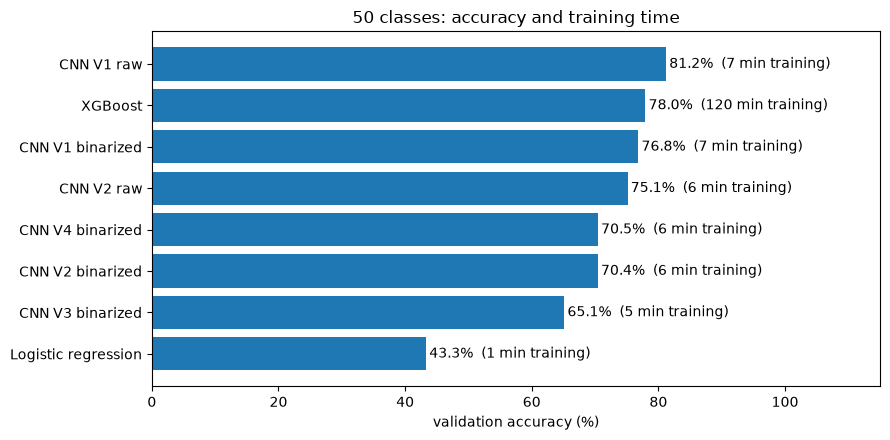

Conclusion: a small CNN (CNN V1 raw) is the most accurate on 50 classes (81.2% in 7 min), while tuned XGBoost reaches 78.0% after 2.0 h.


In [9]:
r50 = runs[runs.classes == 50].drop_duplicates(["family", "model", "input"], keep="last")  # final run per model
r50 = r50[r50.model != "xgb"]  # the first XGBoost run is replaced by the fully trained one
label = r50.family.map({"LR": "Logistic regression", "CNN": "CNN", "XGB": "XGBoost"}) + " " + \
        r50.model.where(r50.family == "CNN", "") + " " + r50.input.where(r50.family == "CNN", "")
r50 = r50.assign(label=label.str.strip()).sort_values("dev_acc")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(r50.label, r50.dev_acc, color="C0")
for y, (acc, t) in enumerate(zip(r50.dev_acc, r50.fit_time_s)):
    ax.text(acc + 0.5, y, f"{acc:.1f}%  ({t / 60:.0f} min training)", va="center")
ax.set(xlim=(0, 115), xlabel="validation accuracy (%)", title="50 classes: accuracy and training time")
plt.tight_layout()
plt.show()

best, xg = r50.iloc[-1], r50[r50.family == "XGB"].iloc[0]
print(f"Conclusion: a small CNN ({best.label}) is the most accurate on 50 classes ({best.dev_acc:.1f}% in "
      f"{best.fit_time_s / 60:.0f} min), while tuned XGBoost reaches {xg.dev_acc:.1f}% after {xg.fit_time_s / 3600:.1f} h.")